# Few-Shot Medical Image Synthesis for Rare Classes

**Idea.** My thesis generated characters of unseen alphabets from five examples with a conditional VAE, but the outputs were blurry. Dr. Behzad's Patch UNet-VAE paper adds a **PatchGAN discriminator** and a **VGG perceptual loss** to VAE reconstruction and trains with synthetic samples. This notebook brings both ideas together for medical images.

**Question.** When a skin-lesion class has only **5 training images**, can a few-shot generative model create useful extra images, and does adversarial + perceptual supervision make them more useful than a plain VAE?

**Data.** HAM10000 dermatoscopic images (`kmader/skin-cancer-mnist-ham10000` on Kaggle, public, no login), resized to 64×64. The split is made **by lesion**, so images of the same lesion never appear in both training and test sets.

**Plan**
1. Pick the two rarest classes and keep only 5 training images (from 5 different lesions) for each. All other classes keep their full training data.
2. Train two few-shot generators. Each takes a support set of images from one class, averages their embeddings into a class vector (as in my thesis FS-CVAE), and generates new images:
   * **FS-CVAE:** L1 reconstruction + KL.
   * **FS-CVAE + PatchGAN + perceptual:** adds a PatchGAN discriminator and a VGG16 perceptual loss.
3. Check the generated images: class fidelity (does an independent classifier recognise the class?), sharpness, and memorisation (are they just copies of the 5 support images?).
4. Train a skin-lesion classifier under five conditions and compare recall on the rare classes:
   **A** 5 rare images only, **B** A + heavy augmentation of the 5 images (strong baseline), **C** A + FS-CVAE images, **D** A + FS-CVAE + PatchGAN + perceptual images, **E** all real images (upper bound).

**Runtime:** Colab T4 GPU, about 60 to 80 minutes.

*Note: HAM10000 is for research only, not for clinical use.*

In [1]:
# 1. Install packages
!pip -q install -U kagglehub

In [2]:
# 2. Settings
import os, glob, random, collections
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from PIL import Image
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor
from sklearn.metrics import balanced_accuracy_score, f1_score, recall_score

SEED        = 42
IMG         = 64
K_SHOT      = 5        # training images kept for each rare class
N_RARE      = 2        # how many of the rarest classes become few-shot classes
N_SYN       = 300      # synthetic (or oversampled) images added per rare class
GEN_STEPS   = 6000
CLS_EPOCHS  = 15
N_SEEDS     = 3
OUT_DIR = '/content/fewshot_medical'
os.makedirs(OUT_DIR, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

Device: cuda


## Step 1. Download HAM10000 and build a lesion-level split

In [3]:
import kagglehub
root = kagglehub.dataset_download('kmader/skin-cancer-mnist-ham10000')
meta_csv = glob.glob(os.path.join(root, '**', 'HAM10000_metadata.csv'), recursive=True)
img_paths = {os.path.splitext(os.path.basename(p))[0]: p
             for p in glob.glob(os.path.join(root, '**', '*.jpg'), recursive=True)}
assert meta_csv and img_paths, 'HAM10000 metadata or images not found in the Kaggle download.'
meta = pd.read_csv(meta_csv[0])
meta = meta[meta.image_id.isin(img_paths)].reset_index(drop=True)
print(len(meta), 'images |', meta.lesion_id.nunique(), 'lesions')

cache = os.path.join(OUT_DIR, f'ham_{IMG}.npy')
def load_img(iid):
    im = Image.open(img_paths[iid]).convert('RGB'); w, h = im.size; s = min(w, h)
    im = im.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s)).resize((IMG, IMG), Image.BICUBIC)
    return np.asarray(im, dtype=np.uint8)
if os.path.exists(cache):
    images = np.load(cache)
else:
    with ThreadPoolExecutor(8) as ex:
        images = np.stack(list(tqdm(ex.map(load_img, meta.image_id), total=len(meta), desc='resize')))
    np.save(cache, images)

CLASSES = sorted(meta.dx.unique()); c2i = {c: i for i, c in enumerate(CLASSES)}
NAMES = {'akiec': 'actinic keratosis', 'bcc': 'basal cell carcinoma', 'bkl': 'benign keratosis',
         'df': 'dermatofibroma', 'mel': 'melanoma', 'nv': 'melanocytic nevus', 'vasc': 'vascular lesion'}
labels = meta.dx.map(c2i).values
N_CLS = len(CLASSES)

100%|██████████| 5.20G/5.20G [00:57<00:00, 97.4MB/s]

Extracting files...


10015 images | 7470 lesions


resize:   0%|          | 0/10015 [00:00<?, ?it/s]

training images per class: {'akiec': np.int64(226), 'bcc': np.int64(351), 'bkl': np.int64(758), 'df': np.int64(84), 'mel': np.int64(792), 'nv': np.int64(4694), 'vasc': np.int64(97)}
few-shot (rare) classes: ['df', 'vasc']
few-shot training set: 6831 images | full training set: 7002 | test: 2011
test images per rare class: {'df': 21, 'vasc': 27}


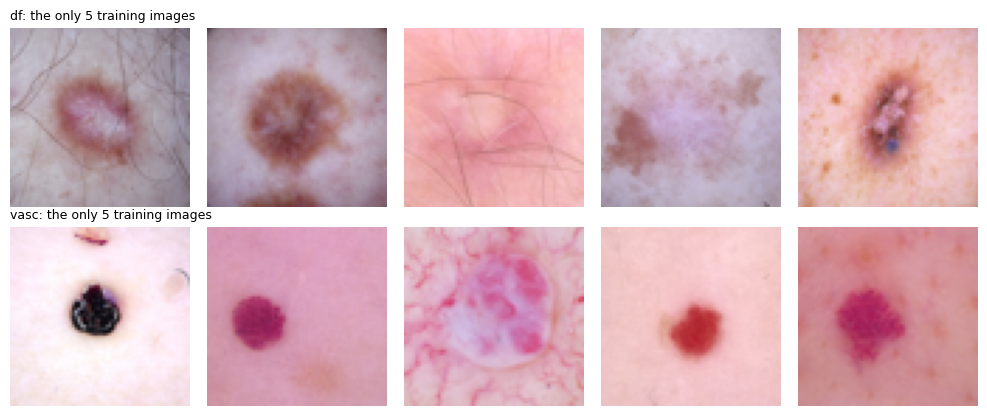

In [4]:
# lesion-level split inside each class: 70% train, 10% validation, 20% test
rng = np.random.RandomState(SEED)
split = np.empty(len(meta), dtype=object)
for c in CLASSES:
    les = np.array(meta.loc[meta.dx == c, 'lesion_id'].unique(), dtype=object); rng.shuffle(les)
    n = len(les); n_te, n_va = int(round(0.2 * n)), int(round(0.1 * n))
    part = {l: 'test' for l in les[:n_te]}
    part.update({l: 'val' for l in les[n_te:n_te + n_va]})
    part.update({l: 'train' for l in les[n_te + n_va:]})
    m = (meta.dx == c).values
    split[m] = meta.loc[m, 'lesion_id'].map(part).values
train_all = np.where(split == 'train')[0]; test_idx = np.where(split == 'test')[0]
assert not set(meta.lesion_id[train_all]) & set(meta.lesion_id[test_idx])

train_counts = np.bincount(labels[train_all], minlength=N_CLS)
RARE = list(np.argsort(train_counts)[:N_RARE])
print('training images per class:', dict(zip(CLASSES, train_counts)))
print('few-shot (rare) classes:', [CLASSES[c] for c in RARE])

# keep K_SHOT images of each rare class, each from a different lesion
fewshot_idx = {}
for c in RARE:
    idx = train_all[labels[train_all] == c]
    first_per_lesion = pd.Series(idx, index=meta.lesion_id.values[idx]).groupby(level=0).first().values
    fewshot_idx[c] = rng.choice(first_per_lesion, K_SHOT, replace=False)
rare_all = np.concatenate([train_all[labels[train_all] == c] for c in RARE])
train_fs = np.concatenate([train_all[~np.isin(labels[train_all], RARE)]] + list(fewshot_idx.values()))
print(f'few-shot training set: {len(train_fs)} images | full training set: {len(train_all)} | test: {len(test_idx)}')
print('test images per rare class:', {CLASSES[c]: int((labels[test_idx] == c).sum()) for c in RARE})

# all images as tensors in [-1, 1]
Xg = torch.tensor(images, dtype=torch.float32, device=device).permute(0, 3, 1, 2) / 127.5 - 1
yg = torch.tensor(labels, device=device)

fig, axes = plt.subplots(N_RARE, K_SHOT, figsize=(2 * K_SHOT, 2.1 * N_RARE))
for r, c in enumerate(RARE):
    for k, i in enumerate(fewshot_idx[c]):
        axes[r, k].imshow(images[i]); axes[r, k].axis('off')
    axes[r, 0].set_title(f'{CLASSES[c]}: the only {K_SHOT} training images', loc='left', fontsize=9)
plt.tight_layout(); plt.show()

## Step 2. Few-shot generators

Both generators share the same architecture:
* a **support encoder** embeds each support image, and the class vector is the **mean** of these embeddings;
* an **encoder** gives the latent code of a query image, given the class vector;
* a **decoder** turns the latent code and the class vector into a 64×64 image.

Training is episodic: each episode picks a class, uses 4 of its images as support and a fifth image as the target. The second generator adds a **PatchGAN discriminator** and a **VGG16 perceptual loss**, the two ingredients of Dr. Behzad's Patch UNet-VAE.

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 169MB/s]


FS-CVAE:   0%|          | 0/6000 [00:00<?, ?it/s]

step 1000: L1 0.1032
step 2000: L1 0.0988
step 3000: L1 0.1012
step 4000: L1 0.0998
step 5000: L1 0.0982
step 6000: L1 0.0976


FS-CVAE + PatchGAN + perceptual:   0%|          | 0/6000 [00:00<?, ?it/s]

step 1000: L1 0.1051
step 2000: L1 0.1023
step 3000: L1 0.1067
step 4000: L1 0.1053
step 5000: L1 0.1038
step 6000: L1 0.1034


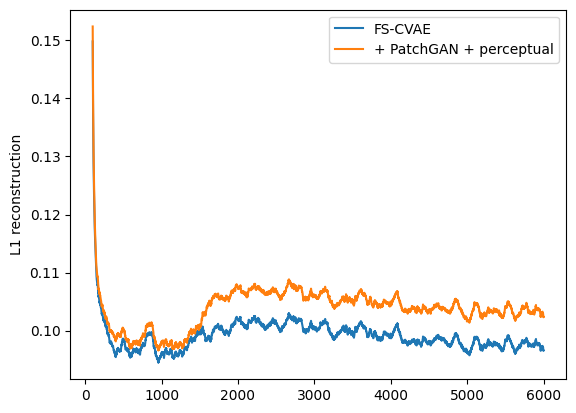

In [5]:
def down(i, o): return nn.Sequential(nn.Conv2d(i, o, 4, 2, 1), nn.BatchNorm2d(o), nn.LeakyReLU(0.2, True))
def up(i, o):   return nn.Sequential(nn.Upsample(scale_factor=2, mode='nearest'), nn.Conv2d(i, o, 3, 1, 1),
                                     nn.BatchNorm2d(o), nn.LeakyReLU(0.2, True))

class ConvEnc(nn.Module):                     # 64x64 image -> vector
    def __init__(self, out):
        super().__init__()
        self.f = nn.Sequential(down(3, 32), down(32, 64), down(64, 128), down(128, 256))
        self.fc = nn.Linear(256 * 4 * 4, out)
    def forward(self, x): return self.fc(self.f(x).flatten(1))

class FewShotCVAE(nn.Module):
    def __init__(self, C=256, Zd=64):
        super().__init__()
        self.Zd = Zd
        self.sup, self.enc = ConvEnc(C), ConvEnc(512)
        self.mu, self.lv = nn.Linear(512 + C, Zd), nn.Linear(512 + C, Zd)
        self.fc = nn.Linear(Zd + C, 256 * 4 * 4)
        self.dec = nn.Sequential(up(256, 256), up(256, 128), up(128, 64), up(64, 32), nn.Conv2d(32, 3, 3, 1, 1), nn.Tanh())
    def cond(self, support):                  # (B, K, 3, H, W) -> (B, C), mean over the support set
        B, K = support.shape[:2]
        return self.sup(support.flatten(0, 1)).view(B, K, -1).mean(1)
    def decode(self, z, c):
        return self.dec(self.fc(torch.cat([z, c], 1)).view(-1, 256, 4, 4))
    def forward(self, x, c):
        h = torch.cat([self.enc(x), c], 1)
        mu, lv = self.mu(h), self.lv(h).clamp(-8, 8)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * lv)
        return self.decode(z, c), mu, lv

SN = nn.utils.spectral_norm
class PatchD(nn.Module):                      # outputs an 8x8 map of real/fake scores
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(SN(nn.Conv2d(3, 64, 4, 2, 1)), nn.LeakyReLU(0.2, True),
                                 SN(nn.Conv2d(64, 128, 4, 2, 1)), nn.LeakyReLU(0.2, True),
                                 SN(nn.Conv2d(128, 256, 4, 2, 1)), nn.LeakyReLU(0.2, True),
                                 SN(nn.Conv2d(256, 1, 3, 1, 1)))
    def forward(self, x): return self.net(x)

vgg = torchvision.models.vgg16(weights=torchvision.models.VGG16_Weights.IMAGENET1K_V1).features[:16].to(device).eval()
for p in vgg.parameters(): p.requires_grad_(False)
IM_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
IM_STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
def perceptual(a, b):
    f = lambda x: vgg(((x + 1) / 2 - IM_MEAN) / IM_STD)
    return F.l1_loss(f(a), f(b))

# episodes: class chosen with probability ~ sqrt(size), 4 support images + 1 target from that class
by_class = {c: train_fs[labels[train_fs] == c] for c in range(N_CLS)}
p_cls = np.array([np.sqrt(len(by_class[c])) for c in range(N_CLS)]); p_cls /= p_cls.sum()
K_TRAIN = K_SHOT - 1
def sample_episodes(B):
    sup, q = [], []
    for c in np.random.choice(N_CLS, B, p=p_cls):
        pick = np.random.choice(by_class[c], K_TRAIN + 1, replace=False)
        sup.append(pick[:K_TRAIN]); q.append(pick[K_TRAIN])
    return torch.tensor(np.array(sup), device=device), torch.tensor(np.array(q), device=device)

BETA_MAX, LAMBDA_PERC, LAMBDA_ADV, ADV_START = 0.002, 0.1, 0.05, 1500
def train_generator(adv, steps=GEN_STEPS, seed=SEED):
    set_seed(seed)
    G = FewShotCVAE().to(device)
    opt_g = torch.optim.Adam(G.parameters(), 2e-4, betas=(0.5, 0.999))
    if adv:
        Dn = PatchD().to(device); opt_d = torch.optim.Adam(Dn.parameters(), 2e-4, betas=(0.5, 0.999))
    log = collections.defaultdict(list)
    for step in tqdm(range(steps), desc='FS-CVAE + PatchGAN + perceptual' if adv else 'FS-CVAE'):
        sup, q = sample_episodes(32)
        xs, xq = Xg[sup], Xg[q]
        if random.random() < 0.5:                 # same random flip for target and support
            xs, xq = xs.flip(-1), xq.flip(-1)
        xh, mu, lv = G(xq, G.cond(xs))
        rec = F.l1_loss(xh, xq)
        kl = (-0.5 * (1 + lv - mu.pow(2) - lv.exp())).sum(1).mean()
        loss = rec + BETA_MAX * min(1.0, step / 2000) * kl
        if adv:
            loss = loss + LAMBDA_PERC * perceptual(xh, xq)
            if step >= ADV_START:
                logit = Dn(xh)
                loss = loss + LAMBDA_ADV * F.binary_cross_entropy_with_logits(logit, torch.ones_like(logit))
        opt_g.zero_grad(); loss.backward(); opt_g.step()
        if adv and step >= ADV_START - 300:
            r, f = Dn(xq), Dn(xh.detach())
            d_loss = F.binary_cross_entropy_with_logits(r, torch.ones_like(r)) + \
                     F.binary_cross_entropy_with_logits(f, torch.zeros_like(f))
            opt_d.zero_grad(); d_loss.backward(); opt_d.step()
        log['rec'].append(rec.item())
        if (step + 1) % 1000 == 0:
            print(f"step {step + 1}: L1 {np.mean(log['rec'][-1000:]):.4f}")
    G.eval()
    return G, log

G_plain, log_plain = train_generator(adv=False)
G_adv, log_adv = train_generator(adv=True)
plt.plot(pd.Series(log_plain['rec']).rolling(100).mean(), label='FS-CVAE')
plt.plot(pd.Series(log_adv['rec']).rolling(100).mean(), label='+ PatchGAN + perceptual')
plt.ylabel('L1 reconstruction'); plt.legend(); plt.show()

## Step 3. Generate images for the rare classes

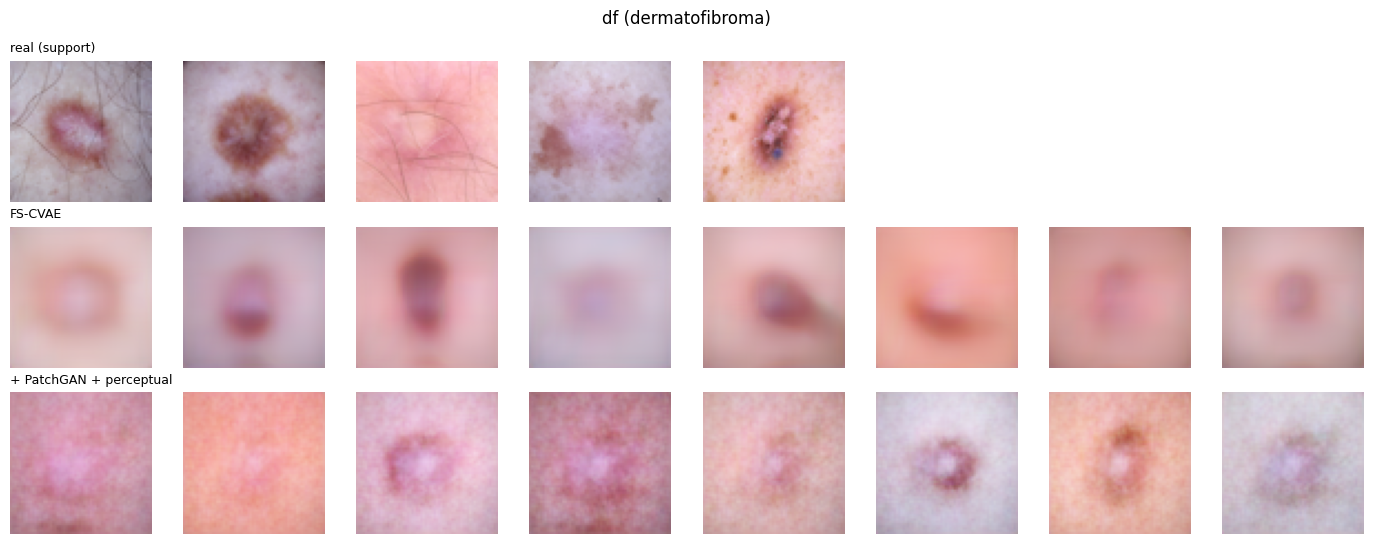

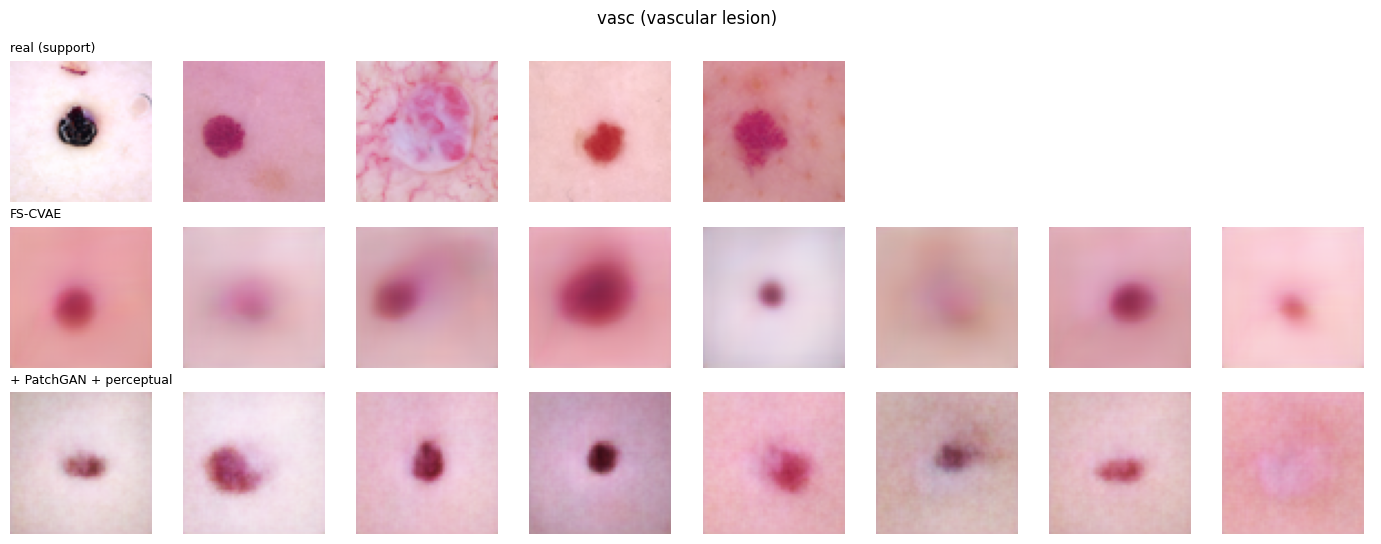

In [6]:
@torch.no_grad()
def synth(G, c, n):
    cvec = G.cond(Xg[torch.tensor(fewshot_idx[c], device=device)][None])
    out = []
    for i in range(0, n, 100):
        z = torch.randn(min(100, n - i), G.Zd, device=device)
        out.append(G.decode(z, cvec.expand(len(z), -1)))
    return torch.cat(out)

SYN = {name: {c: synth(G, c, N_SYN) for c in RARE} for name, G in [('fs_cvae', G_plain), ('fs_cvae_gan', G_adv)]}

def show(t): return ((t.clamp(-1, 1) + 1) / 2).permute(1, 2, 0).cpu().numpy()
for c in RARE:
    fig, axes = plt.subplots(3, 8, figsize=(14, 5.5))
    rows = [('real (support)', Xg[torch.tensor(fewshot_idx[c], device=device)]),
            ('FS-CVAE', SYN['fs_cvae'][c][:8]), ('+ PatchGAN + perceptual', SYN['fs_cvae_gan'][c][:8])]
    for r, (name, imgs) in enumerate(rows):
        for k in range(8):
            axes[r, k].axis('off')
            if k < len(imgs): axes[r, k].imshow(show(imgs[k]))
        axes[r, 0].set_title(name, loc='left', fontsize=9)
    plt.suptitle(f'{CLASSES[c]} ({NAMES.get(CLASSES[c], "")})'); plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, f'samples_{CLASSES[c]}.png'), dpi=150); plt.show()

## Step 4. Classifier and training conditions

A ResNet-18 (ImageNet weights) is trained under each condition with the same settings and `N_SEEDS` seeds. Condition **B** is a strong baseline: the 5 real images are copied with heavy augmentation until they reach the same count as the synthetic images in C and D.

In [7]:
def make_model():
    m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(512, N_CLS); return m.to(device)
def prep(x): return ((x + 1) / 2 - IM_MEAN) / IM_STD
def light_aug(x):
    if random.random() < 0.5: x = x.flip(3)
    if random.random() < 0.5: x = x.flip(2)
    return torch.rot90(x, random.randint(0, 3), (2, 3))
def heavy_aug(x):                                   # used once to build condition B
    x = torch.rot90(x, random.randint(0, 3), (2, 3))
    if random.random() < 0.5: x = x.flip(3)
    x = (x + 1) / 2 * torch.empty(1, 3, 1, 1, device=device).uniform_(0.85, 1.15) \
        + torch.empty(1, 1, 1, 1, device=device).uniform_(-0.08, 0.08)
    shift = np.random.randint(-6, 7, 2)
    x = torch.roll(x, tuple(int(s) for s in shift), (2, 3))
    return x.clamp(0, 1) * 2 - 1

def train_cls(Xtr, ytr, seed, epochs=CLS_EPOCHS):
    set_seed(seed); m = make_model()
    opt = torch.optim.AdamW(m.parameters(), lr=3e-4, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs * (len(Xtr) // 128 + 1))
    for ep in range(epochs):
        m.train()
        for b in torch.randperm(len(Xtr), device=device).split(128):
            loss = F.cross_entropy(m(prep(light_aug(Xtr[b]))), ytr[b])
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return m.eval()

@torch.no_grad()
def predict(m, X):
    return torch.cat([m(prep(X[i:i + 512])).argmax(1) for i in range(0, len(X), 512)])

X_test, y_test = Xg[torch.tensor(test_idx, device=device)], labels[test_idx]
def evaluate(m):
    p = predict(m, X_test).cpu().numpy()
    rec = recall_score(y_test, p, labels=list(range(N_CLS)), average=None, zero_division=0)
    return dict(balanced_acc=100 * balanced_accuracy_score(y_test, p),
                macro_f1=100 * f1_score(y_test, p, average='macro'),
                rare_recall=100 * np.mean([rec[c] for c in RARE]),
                **{f'recall_{CLASSES[c]}': 100 * rec[c] for c in RARE}), p

def idx_t(ix): return torch.tensor(np.asarray(ix), device=device)
base_X, base_y = Xg[idx_t(train_fs)], yg[idx_t(train_fs)]
def with_extra(extra):           # extra: {class: tensor of images}
    xs = [base_X] + [extra[c] for c in RARE]
    ys = [base_y] + [torch.full((len(extra[c]),), int(c), device=device) for c in RARE]
    return torch.cat(xs), torch.cat(ys)
oversampled = {c: torch.stack([heavy_aug(Xg[int(i)][None])[0] for i in np.resize(fewshot_idx[c], N_SYN)]) for c in RARE}

CONDITIONS = {
    'A: 5 rare images':             (base_X, base_y),
    'B: + heavy augmentation':      with_extra(oversampled),
    'C: + FS-CVAE images':          with_extra(SYN['fs_cvae']),
    'D: + FS-CVAE-GAN images':      with_extra(SYN['fs_cvae_gan']),
    'E: all real images (upper bound)': (Xg[idx_t(train_all)], yg[idx_t(train_all)]),
}
for k, (x, _) in CONDITIONS.items(): print(f'{k:36s} {len(x)} training images')

A: 5 rare images                     6831 training images
B: + heavy augmentation              7431 training images
C: + FS-CVAE images                  7431 training images
D: + FS-CVAE-GAN images              7431 training images
E: all real images (upper bound)     7002 training images


## Step 5. Quality of the generated images

In [8]:
# an independent classifier trained on ALL real training images judges the generated images
oracle = train_cls(Xg[idx_t(train_all)], yg[idx_t(train_all)], seed=SEED + 100)

def sharpness(x):                              # variance of the Laplacian on grey images
    g = ((x + 1) / 2).mean(1, keepdim=True)
    k = torch.tensor([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=torch.float32, device=device).view(1, 1, 3, 3)
    return F.conv2d(g, k).flatten(1).var(1).mean().item()

def nn_dist(x, ref):                           # mean distance to the closest reference image
    return torch.cdist(x.flatten(1), ref.flatten(1)).min(1).values.mean().item()

rows = []
for c in RARE:
    sup = Xg[idx_t(fewshot_idx[c])]
    real_test = X_test[torch.tensor(y_test == c, device=device)]
    real_nn = nn_dist(real_test, sup)
    rows.append(dict(cls=CLASSES[c], source='real test images', fidelity=100 * (predict(oracle, real_test) == c).float().mean().item(),
                     sharpness=sharpness(real_test), nn_to_support=real_nn, copy_ratio=1.0))
    for name in ['fs_cvae', 'fs_cvae_gan']:
        s = SYN[name][c]
        d = nn_dist(s, sup)
        rows.append(dict(cls=CLASSES[c], source=name, fidelity=100 * (predict(oracle, s) == c).float().mean().item(),
                         sharpness=sharpness(s), nn_to_support=d, copy_ratio=d / real_nn))
quality = pd.DataFrame(rows); quality.to_csv(os.path.join(OUT_DIR, 'generation_quality.csv'), index=False)
print('fidelity   = % of images the independent classifier assigns to the intended class')
print('sharpness  = Laplacian variance (higher = sharper)')
print('copy_ratio = distance to the 5 support images, relative to real test images (much below 1 = copying)')
quality.round(3)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s]


fidelity   = % of images the independent classifier assigns to the intended class
sharpness  = Laplacian variance (higher = sharper)
copy_ratio = distance to the 5 support images, relative to real test images (much below 1 = copying)


,cls,source,fidelity,sharpness,nn_to_support,copy_ratio
0,df,real test images,47.619,0.003,27.048,1.000
1,df,fs_cvae,0.000,0.000,22.472,0.831
2,df,fs_cvae_gan,66.667,0.001,22.675,0.838
3,vasc,real test images,88.889,0.003,29.684,1.000
4,vasc,fs_cvae,30.667,0.000,23.321,0.786
5,vasc,fs_cvae_gan,72.000,0.001,23.464,0.790


## Step 6. Train and evaluate the classifier under all conditions

In [9]:
results, preds = [], {}
for name, (Xc, yc) in CONDITIONS.items():
    runs = []
    for k in range(N_SEEDS):
        m = train_cls(Xc, yc, SEED + k)
        r, p = evaluate(m); runs.append(r); preds[(name, k)] = p
        del m; torch.cuda.empty_cache()
    df = pd.DataFrame(runs)
    row = {'condition': name, **{c: df[c].mean() for c in df}, 'rare_recall_sd': df['rare_recall'].std()}
    results.append(row)
    print(f"{name:36s} rare recall {row['rare_recall']:5.1f} ± {row['rare_recall_sd']:.1f} | "
          f"balanced acc {row['balanced_acc']:5.1f} | macro F1 {row['macro_f1']:5.1f}")
res = pd.DataFrame(results); res.to_csv(os.path.join(OUT_DIR, 'classification_results.csv'), index=False)
res.round(2)

A: 5 rare images                     rare recall  16.7 ± 1.9 | balanced acc  46.9 | macro F1  49.6
B: + heavy augmentation              rare recall  25.5 ± 2.4 | balanced acc  50.8 | macro F1  53.3
C: + FS-CVAE images                  rare recall  26.5 ± 1.1 | balanced acc  50.6 | macro F1  52.7
D: + FS-CVAE-GAN images              rare recall  24.8 ± 1.6 | balanced acc  49.2 | macro F1  52.2
E: all real images (upper bound)     rare recall  66.8 ± 6.1 | balanced acc  60.2 | macro F1  62.5


,condition,balanced_acc,macro_f1,rare_recall,recall_df,recall_vasc,rare_recall_sd
0,A: 5 rare images,46.88,49.58,16.67,0.00,33.33,1.85
1,B: + heavy augmentation,50.81,53.25,25.49,1.59,49.38,2.44
2,C: + FS-CVAE images,50.61,52.71,26.54,0.00,53.09,1.07
3,D: + FS-CVAE-GAN images,49.24,52.25,24.78,6.35,43.21,1.59
4,E: all real images (upper bound),60.22,62.52,66.84,46.03,87.65,6.13


D minus B: -1.4 recall points on rare classes (95% CI -6.9 to +4.2)
D minus C: -2.8 recall points on rare classes (95% CI -9.0 to +3.5)
C minus B: +1.4 recall points on rare classes (95% CI -2.8 to +5.6)


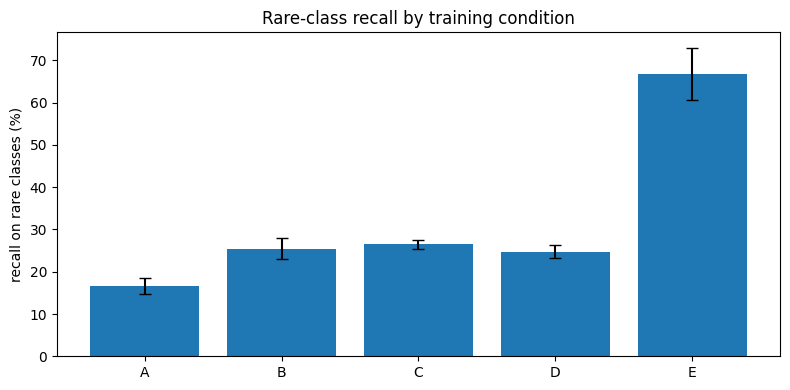

In [10]:
# paired bootstrap on the rare-class test images (correctness averaged over seeds)
rare_mask = np.isin(y_test, RARE)
def correct(name): return np.mean([(preds[(name, k)] == y_test)[rare_mask] for k in range(N_SEEDS)], 0)
def paired(a, b, n=5000):
    d = correct(a) - correct(b); idx = np.random.randint(0, len(d), (n, len(d)))
    m = d[idx].mean(1); return 100 * d.mean(), 100 * np.percentile(m, [2.5, 97.5])
names = list(CONDITIONS)
for a, b in [(names[3], names[1]), (names[3], names[2]), (names[2], names[1])]:
    m, (lo, hi) = paired(a, b)
    print(f'{a[:1]} minus {b[:1]}: {m:+.1f} recall points on rare classes (95% CI {lo:+.1f} to {hi:+.1f})')

plt.figure(figsize=(8, 4))
plt.bar([n[:1] for n in res.condition], res.rare_recall, yerr=res.rare_recall_sd, capsize=4)
plt.ylabel('recall on rare classes (%)'); plt.title('Rare-class recall by training condition')
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'rare_recall.png'), dpi=150); plt.show()

## Step 7. Save everything

In [11]:
torch.save({'fs_cvae': G_plain.state_dict(), 'fs_cvae_gan': G_adv.state_dict(), 'classes': CLASSES,
            'rare': [CLASSES[c] for c in RARE], 'fewshot_image_ids': {CLASSES[c]: meta.image_id[fewshot_idx[c]].tolist() for c in RARE}},
           os.path.join(OUT_DIR, 'generators.pt'))
import shutil
for f in glob.glob(os.path.join(OUT_DIR, '*.npy')): os.remove(f)      # keep the zip small
shutil.make_archive('/content/fewshot_medical_results', 'zip', OUT_DIR)
print('Saved: /content/fewshot_medical_results.zip')
try:
    from google.colab import files
    files.download('/content/fewshot_medical_results.zip')
except Exception:
    pass

Saved: /content/fewshot_medical_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes for writing up the results

* **Lesion-level split.** Training and test sets never share a lesion, which avoids the leakage that is common with HAM10000.
* **The fair comparison is D against B.** Both add the same number of images built from the same 5 real images. If D is higher, the generator adds something that augmentation alone does not.
* **D against C** is the ablation for adversarial + perceptual supervision, the main idea taken from the Patch UNet-VAE paper.
* **Check copying.** If `copy_ratio` is far below 1, the generator is mostly copying the 5 support images, and any gain may just be augmentation.
* **Limits.** 64×64 images, one dataset, one classifier, and the rare classes are seen by the generator during training (only their 5 images). A stronger next test leaves the rare classes out of generator training completely, or moves to chest X-rays.